In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt


In [ ]:
TRAIN_PATH = "/content/drive/MyDrive/flower14/14 type flower/train"
VAL_PATH   = "/content/drive/MyDrive/flower14/14 type flower/val"

IMG_SIZE = 128
BATCH_SIZE = 32


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

train_data = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse'
)

val_data = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse'
)


Found 13642 images belonging to 14 classes.
Found 98 images belonging to 14 classes.


In [ ]:
model = Sequential([
    Flatten(input_shape=(IMG_SIZE, IMG_SIZE, 3)),

    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation='relu'),
    Dropout(0.2),

    Dense(14, activation='softmax')  # 14 flower classes
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20
)

Epoch 1/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 1818s 4s/step - accuracy: 0.2994 - loss: 2.1183 - val_accuracy: 0.2959 - val_loss: 1.8686
Epoch 2/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 266s 623ms/step - accuracy: 0.3286 - loss: 1.9246 - val_accuracy: 0.3163 - val_loss: 1.7090
Epoch 3/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 269s 630ms/step - accuracy: 0.3704 - loss: 1.8186 - val_accuracy: 0.3980 - val_loss: 1.6327
Epoch 4/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 271s 634ms/step - accuracy: 0.3905 - loss: 1.7556 - val_accuracy: 0.3776 - val_loss: 1.5975
Epoch 5/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 268s 627ms/step - accuracy: 0.3959 - loss: 1.7188 - val_accuracy: 0.3878 - val_loss: 1.6842
Epoch 6/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 270s 632ms/step - accuracy: 0.4143 - loss: 1.6948 - val_accuracy: 0.3776 - val_loss: 1.7595
Epoch 7/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 273s 639ms/step - accuracy: 0.4208 - loss: 1.6462 - val_accuracy: 0.4184 - val_loss: 1.5609
Epoch 8/20
427/427 ━━━━━━━━━━━━━━━━━━━━ 293s 685ms/step - accuracy: 0.4301 - l

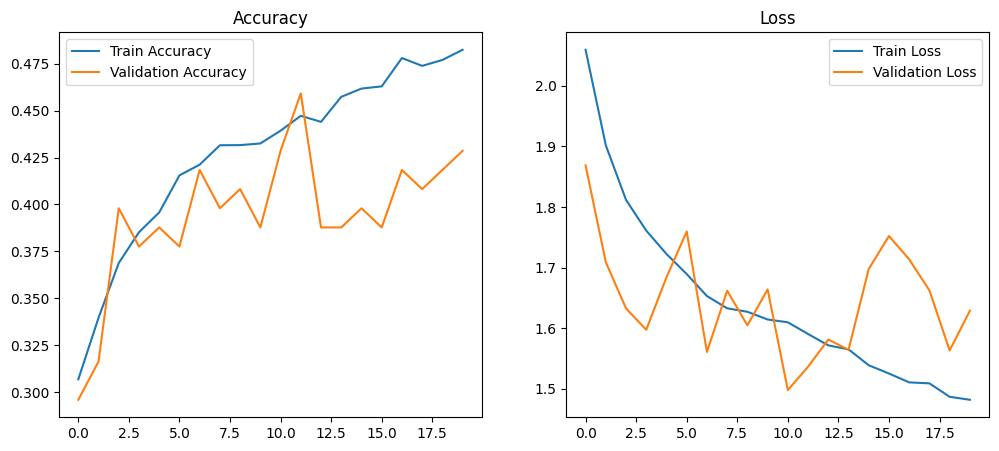

In [ ]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()
